In [19]:

# STEP 1: IMPORT REQUIRED LIBRARIES

import pandas as pd
import numpy as np

import os

print("Libraries imported successfully!")
import matplotlib.pyplot as plt
from google.colab import files
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")


Libraries imported successfully!
All libraries imported successfully!


In [2]:
# Step 2: Upload the cleaned hospital dataset

uploaded = files.upload()

file_name = next(iter(uploaded.keys()))

print("Uploaded file:", file_name)

Saving HospitalOPD_CareFlow_cleaned_v4.xlsx to HospitalOPD_CareFlow_cleaned_v4.xlsx
Uploaded file: HospitalOPD_CareFlow_cleaned_v4.xlsx


In [3]:
# Step 3: Load the cleaned dataset from Excel

df = pd.read_excel(
    file_name,
    sheet_name="Cleaned_Data"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (62422, 50)


In [4]:
# Step 4: Display all dataset columns

for col in df.columns:
    print(col)

record_no
patient_id
appointment_id
appointment_start_datetime
prescription_doctor_id
prescription_doctor_name
prescription_order_id
prescription_start_datetime
prescription_end_datetime
lab_id
lab_name
lab_start_datetime
lab_end_datetime
imaging_request_id
imaging_result_id
imaging_name
imaging_start_datetime
imaging_end_datetime
pharmacy_sale_line_id
medicine_name
pharmacy_start_datetime
pharmacy_end_datetime
flow_code
flow_name
appointment_start_datetime_original
appointment_start_datetime_parse_issue
prescription_start_datetime_original
prescription_start_datetime_parse_issue
prescription_end_datetime_original
prescription_end_datetime_parse_issue
lab_start_datetime_original
lab_start_datetime_parse_issue
lab_end_datetime_original
lab_end_datetime_parse_issue
imaging_start_datetime_original
imaging_start_datetime_parse_issue
imaging_end_datetime_original
imaging_end_datetime_parse_issue
pharmacy_start_datetime_original
pharmacy_start_datetime_parse_issue
pharmacy_end_datetime_origi

In [5]:
# Step 5: Check missing values and duplicate records

print("Total Rows:", len(df))

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

Total Rows: 62422

Duplicate Rows: 0

Missing Values:
lab_start_datetime_parse_issue             62422
appointment_start_datetime_parse_issue     62422
imaging_start_datetime_parse_issue         62422
imaging_end_datetime_parse_issue           62422
pharmacy_end_datetime_parse_issue          62422
pharmacy_start_datetime_parse_issue        62422
prescription_start_datetime_parse_issue    62422
prescription_end_datetime_parse_issue      62422
duplicate_group_id                         62414
pharmacy_end_datetime                      62120
pharmacy_end_datetime_original             62120
medicine_name                              62120
pharmacy_sale_line_id                      62120
pharmacy_start_datetime                    62120
pharmacy_start_datetime_original           62120
lab_end_datetime_parse_issue               57720
imaging_end_datetime                       56909
imaging_end_datetime_original              56909
imaging_name                               56899
imaging_start_d

In [6]:
# Step 6: Convert lab, imaging and pharmacy timestamps

date_columns = [
    "lab_start_datetime",
    "lab_end_datetime",
    "imaging_start_datetime",
    "imaging_end_datetime",
    "pharmacy_start_datetime",
    "pharmacy_end_datetime"
]

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        errors="coerce",
        format="mixed"
    )

print("Date conversion completed!")

Date conversion completed!


In [7]:
# Step 7: Create separate event-level datasets

lab_df = df.dropna(subset=["lab_id"]).groupby("lab_id", as_index=False).agg(
    lab_name=("lab_name", "first"),
    start=("lab_start_datetime", "min"),
    end=("lab_end_datetime", "max")
)

imaging_df = df.dropna(subset=["imaging_request_id"]).groupby("imaging_request_id", as_index=False).agg(
    imaging_result_id=("imaging_result_id", "first"),
    imaging_name=("imaging_name", "first"),
    start=("imaging_start_datetime", "min"),
    end=("imaging_end_datetime", "max")
)

pharmacy_df = df.dropna(subset=["pharmacy_sale_line_id"]).groupby("pharmacy_sale_line_id", as_index=False).agg(
    medicine_name=("medicine_name", "first"),
    start=("pharmacy_start_datetime", "min"),
    end=("pharmacy_end_datetime", "max")
)

print("Lab records:", len(lab_df))
print("Imaging records:", len(imaging_df))
print("Pharmacy records:", len(pharmacy_df))

Lab records: 17083
Imaging records: 5360
Pharmacy records: 262


In [8]:
# Step 8: Calculate processing duration in minutes

lab_df["duration_minutes"] = (
    lab_df["end"] - lab_df["start"]
).dt.total_seconds() / 60

imaging_df["duration_minutes"] = (
    imaging_df["end"] - imaging_df["start"]
).dt.total_seconds() / 60

pharmacy_df["duration_minutes"] = (
    pharmacy_df["end"] - pharmacy_df["start"]
).dt.total_seconds() / 60

print("Processing duration calculated!")

Processing duration calculated!


In [9]:
# Step 9: Generate laboratory summary statistics

print("Total Lab IDs:", lab_df["lab_id"].nunique())

print("Total Lab Names:", lab_df["lab_name"].nunique())

print("\nLab Duration Statistics:")
print(lab_df["duration_minutes"].describe())

print("\nTop 10 Lab Activities:")
print(lab_df["lab_name"].value_counts().head(10))

Total Lab IDs: 17083
Total Lab Names: 119

Lab Duration Statistics:
count     12731.000000
mean       3120.370513
std       19916.685943
min           0.000000
25%          79.000000
50%         129.000000
75%         227.000000
max      286633.000000
Name: duration_minutes, dtype: float64

Top 10 Lab Activities:
lab_name
Complete Blood Count           4761
Urine R/E                      1687
Liver Function Test             736
TSH                             733
Glycosylated Hb (HbA1c)         714
Renal Function Tests (RFTs)     659
HCV Ab by ICT                   616
HBsAg By ICT                    594
CRP- C Reactive Proteins        440
Glucose Random                  440
Name: count, dtype: int64


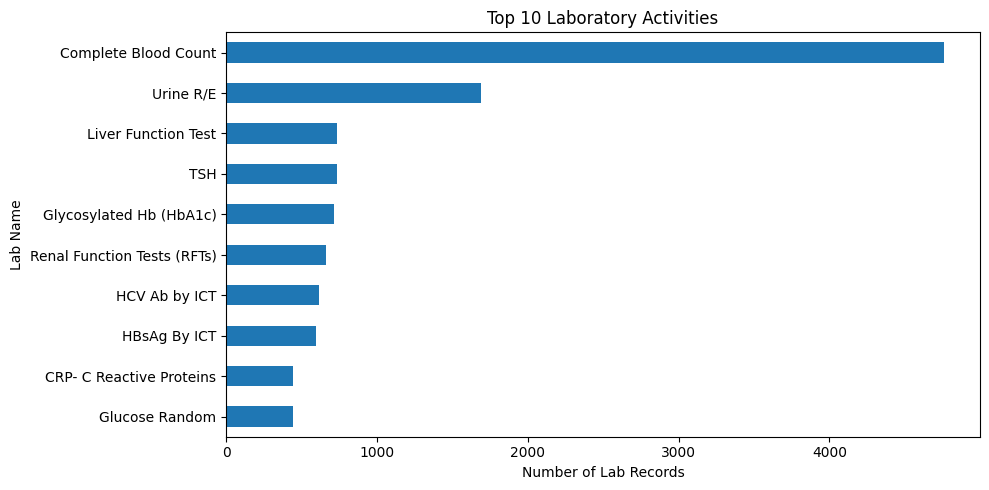

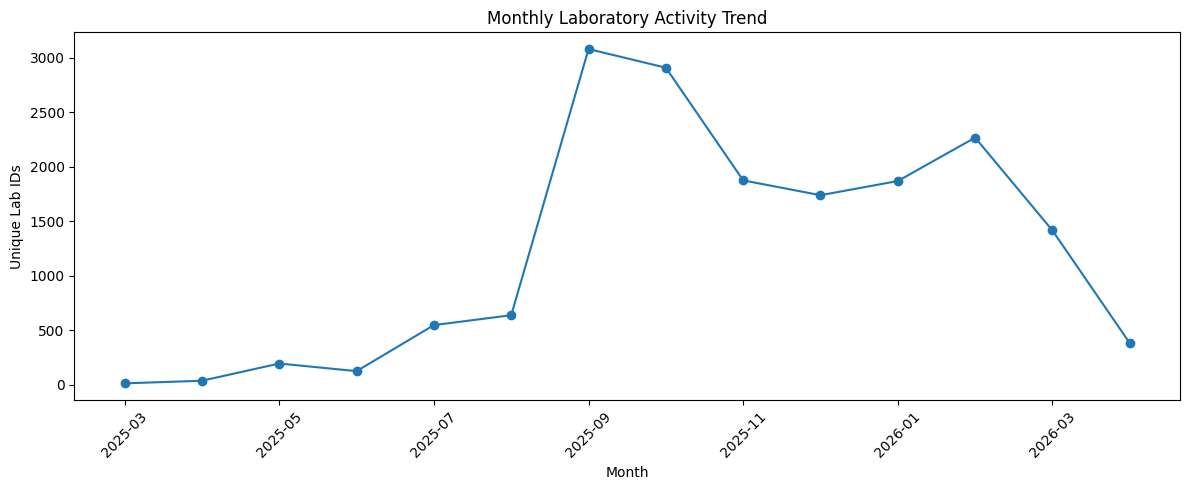

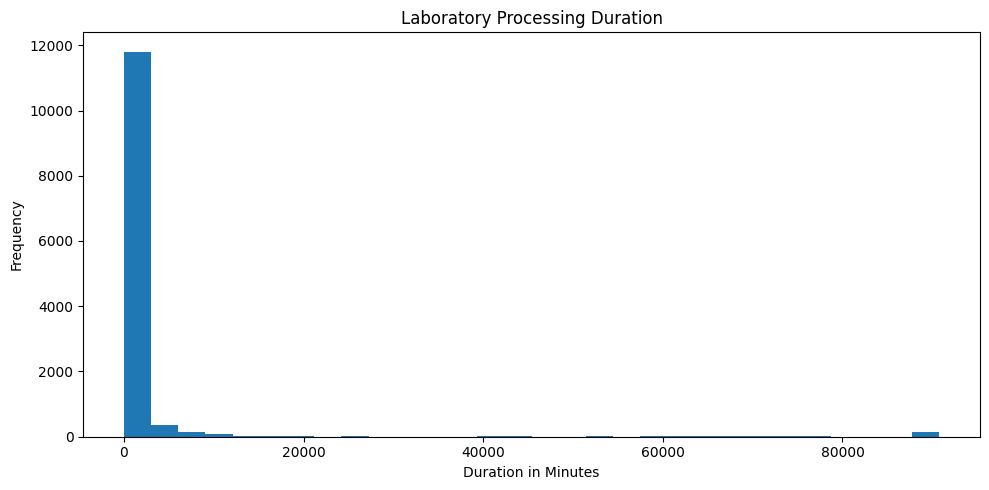

In [10]:
# Step 10: Create laboratory analysis charts

# Chart 1: Top 10 Lab Activities
top_lab = lab_df["lab_name"].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_lab.sort_values().plot(kind="barh")
plt.title("Top 10 Laboratory Activities")
plt.xlabel("Number of Lab Records")
plt.ylabel("Lab Name")
plt.tight_layout()
plt.savefig("01_top_lab_activities.png")
plt.show()

# Chart 2: Monthly Lab Trend
lab_df["month"] = lab_df["start"].dt.to_period("M").astype(str)

monthly_lab = lab_df.groupby("month")["lab_id"].nunique()

plt.figure(figsize=(12, 5))
monthly_lab.plot(kind="line", marker="o")
plt.title("Monthly Laboratory Activity Trend")
plt.xlabel("Month")
plt.ylabel("Unique Lab IDs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("02_monthly_lab_trend.png")
plt.show()

# Chart 3: Lab Processing Duration
valid_lab_duration = lab_df.loc[
    lab_df["duration_minutes"] > 0, "duration_minutes"
].dropna()

if not valid_lab_duration.empty:
    plt.figure(figsize=(10, 5))
    valid_lab_duration.clip(
        upper=valid_lab_duration.quantile(0.99)
    ).plot(kind="hist", bins=30)
    plt.title("Laboratory Processing Duration")
    plt.xlabel("Duration in Minutes")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig("03_lab_duration.png")
    plt.show()

In [11]:
# Step 11: Generate imaging summary statistics

print("Total Imaging Requests:", imaging_df["imaging_request_id"].nunique())

print("Total Imaging Results:", imaging_df["imaging_result_id"].nunique())

print("Total Imaging Names:", imaging_df["imaging_name"].nunique())

print("\nImaging Duration Statistics:")
print(imaging_df["duration_minutes"].describe())

print("\nTop 10 Imaging Activities:")
print(imaging_df["imaging_name"].value_counts().head(10))

Total Imaging Requests: 5360
Total Imaging Results: 5360
Total Imaging Names: 37

Imaging Duration Statistics:
count      5352.000000
mean         98.991779
std        2346.782022
min           0.000000
25%           1.000000
50%           3.000000
75%           5.000000
max      101753.000000
Name: duration_minutes, dtype: float64

Top 10 Imaging Activities:
imaging_name
FWB                   2255
pelvis(Ultrasound)    1312
Abdomen Ultrasound     525
Anomaly-Fetal          399
Abdomen & Pelvis       174
Doppler Fetal          126
KUB Ultrasound         123
TVS-Vaginal             71
N T Scan                67
Kub & Pelvis            40
Name: count, dtype: int64


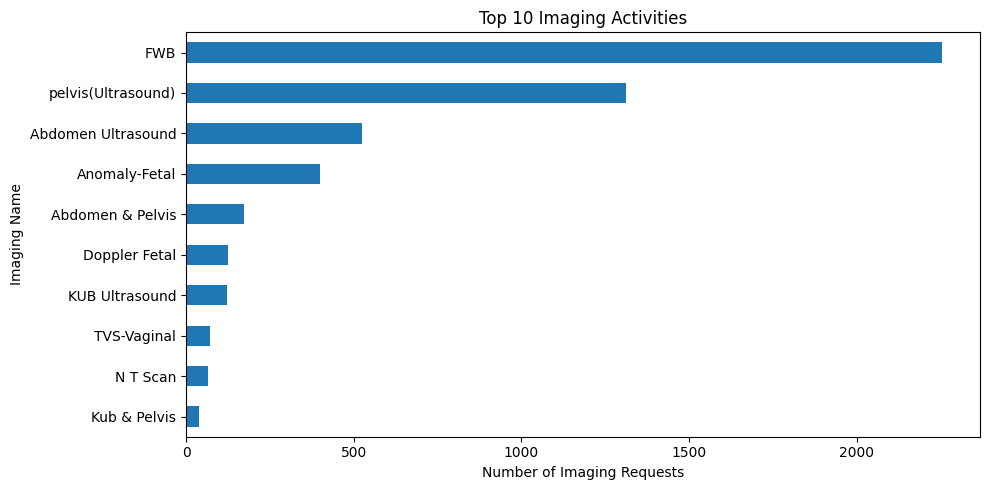

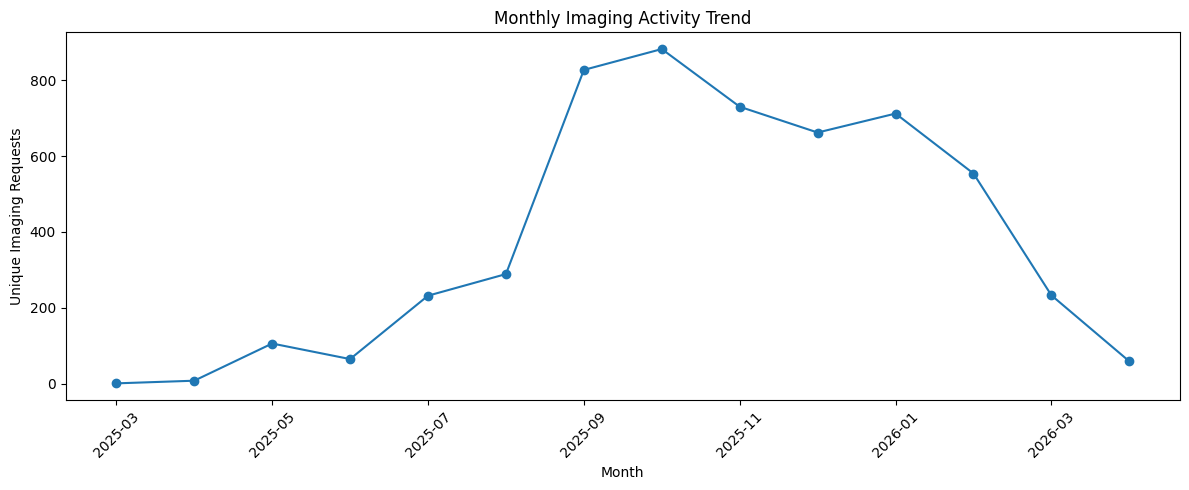

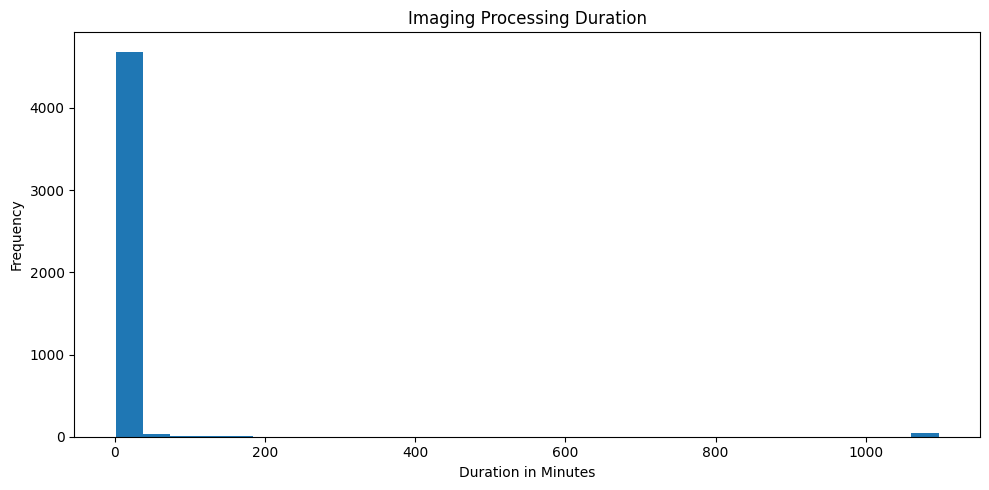

In [12]:
# Step 12: Create imaging analysis charts

# Chart 1: Top 10 Imaging Activities
top_imaging = imaging_df["imaging_name"].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_imaging.sort_values().plot(kind="barh")
plt.title("Top 10 Imaging Activities")
plt.xlabel("Number of Imaging Requests")
plt.ylabel("Imaging Name")
plt.tight_layout()
plt.savefig("04_top_imaging_activities.png")
plt.show()

# Chart 2: Monthly Imaging Trend
imaging_df["month"] = imaging_df["start"].dt.to_period("M").astype(str)

monthly_imaging = imaging_df.groupby("month")["imaging_request_id"].nunique()

plt.figure(figsize=(12, 5))
monthly_imaging.plot(kind="line", marker="o")
plt.title("Monthly Imaging Activity Trend")
plt.xlabel("Month")
plt.ylabel("Unique Imaging Requests")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("05_monthly_imaging_trend.png")
plt.show()

# Chart 3: Imaging Processing Duration
valid_imaging_duration = imaging_df.loc[
    imaging_df["duration_minutes"] > 0, "duration_minutes"
].dropna()

if not valid_imaging_duration.empty:
    plt.figure(figsize=(10, 5))
    valid_imaging_duration.clip(
        upper=valid_imaging_duration.quantile(0.99)
    ).plot(kind="hist", bins=30)
    plt.title("Imaging Processing Duration")
    plt.xlabel("Duration in Minutes")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig("06_imaging_duration.png")
    plt.show()

In [13]:
# Step 13: Generate pharmacy summary statistics

print("Total Pharmacy Sale Lines:", pharmacy_df["pharmacy_sale_line_id"].nunique())

print("Total Unique Medicines:", pharmacy_df["medicine_name"].nunique())

print("\nPharmacy Duration Statistics:")
print(pharmacy_df["duration_minutes"].describe())

print("\nTop 10 Medicines:")
print(pharmacy_df["medicine_name"].value_counts().head(10))

Total Pharmacy Sale Lines: 262
Total Unique Medicines: 147

Pharmacy Duration Statistics:
count    262.000000
mean       6.083969
std       61.596641
min        0.000000
25%        0.000000
50%        1.000000
75%        1.000000
max      707.000000
Name: duration_minutes, dtype: float64

Top 10 Medicines:
medicine_name
Histazolin Eye Drop - 5 mL OP          10
Soda Glycerine Ear Drop - 10 mL MTH     6
Risek 40 mg Inf - 1 Vial IV MTH         6
Normal Saline 500ML MTH                 5
Jikoside 4mg/2ml inj 5s                 5
Voren 75 mg/mL Inj - 100 Ampx3 mL       5
Panadol Tab 500 mg                      5
Nospa Fort Tablet 30 s MTH              4
Nospa 40mg Tablet -MTH                  4
Nospa Injection -MTH                    4
Name: count, dtype: int64


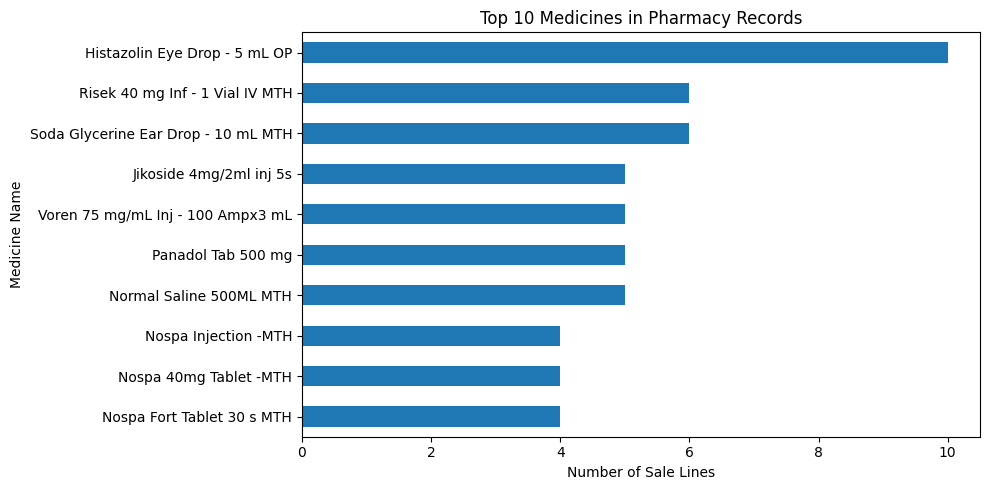

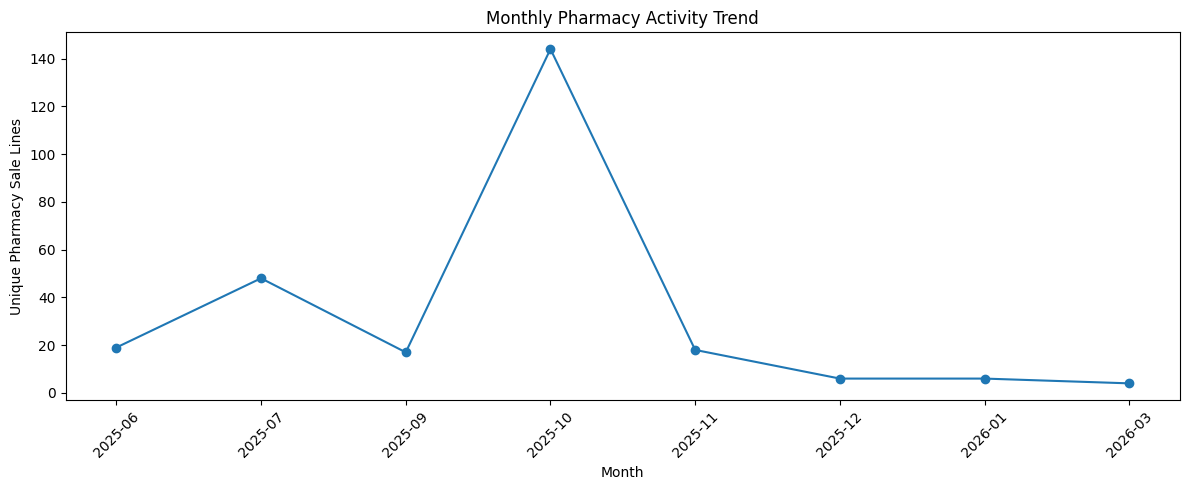

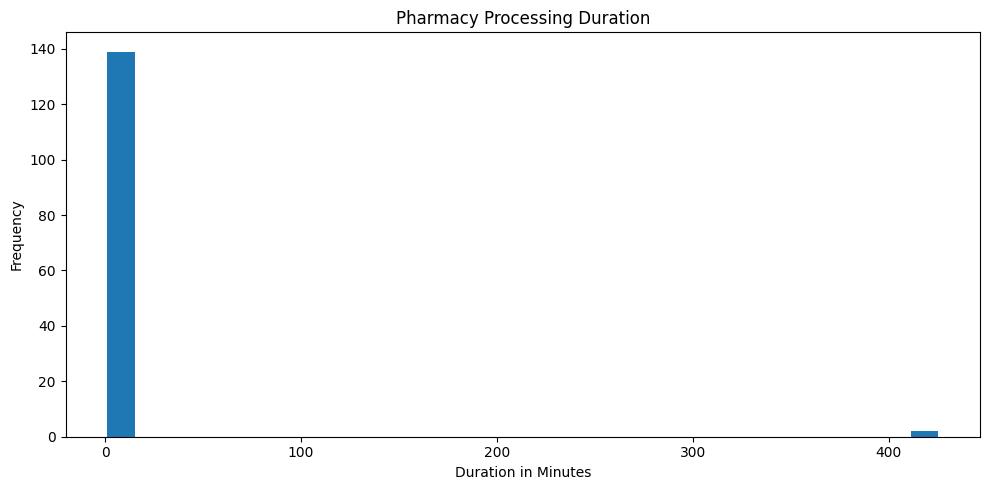

In [14]:
# Step 14: Create pharmacy analysis charts

# Chart 1: Top 10 Medicines
top_medicines = pharmacy_df["medicine_name"].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_medicines.sort_values().plot(kind="barh")
plt.title("Top 10 Medicines in Pharmacy Records")
plt.xlabel("Number of Sale Lines")
plt.ylabel("Medicine Name")
plt.tight_layout()
plt.savefig("07_top_medicines.png")
plt.show()

# Chart 2: Monthly Pharmacy Trend
pharmacy_df["month"] = pharmacy_df["start"].dt.to_period("M").astype(str)

monthly_pharmacy = pharmacy_df.groupby("month")["pharmacy_sale_line_id"].nunique()

plt.figure(figsize=(12, 5))
monthly_pharmacy.plot(kind="line", marker="o")
plt.title("Monthly Pharmacy Activity Trend")
plt.xlabel("Month")
plt.ylabel("Unique Pharmacy Sale Lines")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("08_monthly_pharmacy_trend.png")
plt.show()

# Chart 3: Pharmacy Processing Duration
valid_pharmacy_duration = pharmacy_df.loc[
    pharmacy_df["duration_minutes"] > 0, "duration_minutes"
].dropna()

if not valid_pharmacy_duration.empty:
    plt.figure(figsize=(10, 5))
    valid_pharmacy_duration.clip(
        upper=valid_pharmacy_duration.quantile(0.99)
    ).plot(kind="hist", bins=30)
    plt.title("Pharmacy Processing Duration")
    plt.xlabel("Duration in Minutes")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig("09_pharmacy_duration.png")
    plt.show()

In [15]:
# Step 15: Generate data quality report for all three departments

quality_report = pd.DataFrame({
    "Department": ["Lab", "Imaging", "Pharmacy"],
    "Total_Rows": [
        df["lab_id"].notna().sum(),
        df["imaging_request_id"].notna().sum(),
        df["pharmacy_sale_line_id"].notna().sum()
    ],
    "Unique_IDs": [
        lab_df["lab_id"].nunique(),
        imaging_df["imaging_request_id"].nunique(),
        pharmacy_df["pharmacy_sale_line_id"].nunique()
    ],
    "Missing_Start": [
        lab_df["start"].isna().sum(),
        imaging_df["start"].isna().sum(),
        pharmacy_df["start"].isna().sum()
    ],
    "Missing_End": [
        lab_df["end"].isna().sum(),
        imaging_df["end"].isna().sum(),
        pharmacy_df["end"].isna().sum()
    ],
    "Negative_Duration": [
        (lab_df["duration_minutes"] < 0).sum(),
        (imaging_df["duration_minutes"] < 0).sum(),
        (pharmacy_df["duration_minutes"] < 0).sum()
    ],
    "Zero_Duration": [
        (lab_df["duration_minutes"] == 0).sum(),
        (imaging_df["duration_minutes"] == 0).sum(),
        (pharmacy_df["duration_minutes"] == 0).sum()
    ]
})

print(quality_report)

  Department  Total_Rows  Unique_IDs  Missing_Start  Missing_End  \
0        Lab       18029       17083              0         4352   
1    Imaging        5523        5360              0            8   
2   Pharmacy         302         262              0            0   

   Negative_Duration  Zero_Duration  
0                  0              1  
1                  0            547  
2                  0            121  


In [16]:
# Step 16: Save department-wise summary reports

lab_summary = pd.DataFrame({
    "Metric": ["Total Lab IDs", "Unique Lab Names", "Median Duration"],
    "Value": [
        lab_df["lab_id"].nunique(),
        lab_df["lab_name"].nunique(),
        lab_df["duration_minutes"].median()
    ]
})

imaging_summary = pd.DataFrame({
    "Metric": ["Total Imaging Requests", "Unique Imaging Names", "Median Duration"],
    "Value": [
        imaging_df["imaging_request_id"].nunique(),
        imaging_df["imaging_name"].nunique(),
        imaging_df["duration_minutes"].median()
    ]
})

pharmacy_summary = pd.DataFrame({
    "Metric": ["Total Pharmacy Sale Lines", "Unique Medicines", "Median Duration"],
    "Value": [
        pharmacy_df["pharmacy_sale_line_id"].nunique(),
        pharmacy_df["medicine_name"].nunique(),
        pharmacy_df["duration_minutes"].median()
    ]
})

lab_summary.to_csv("lab_summary.csv", index=False)
imaging_summary.to_csv("imaging_summary.csv", index=False)
pharmacy_summary.to_csv("pharmacy_summary.csv", index=False)

quality_report.to_csv("department_quality_report.csv", index=False)

print("All summary reports saved successfully!")

All summary reports saved successfully!


In [17]:
# Step 17: Export department-wise event datasets

lab_df.to_csv("lab_detailed_analysis.csv", index=False)

imaging_df.to_csv("imaging_detailed_analysis.csv", index=False)

pharmacy_df.to_csv("pharmacy_detailed_analysis.csv", index=False)

print("Detailed reports exported successfully!")

Detailed reports exported successfully!


In [20]:
# Step 18: Download all analysis outputs

output_files = [
    "01_top_lab_activities.png",
    "02_monthly_lab_trend.png",
    "03_lab_duration.png",
    "04_top_imaging_activities.png",
    "05_monthly_imaging_trend.png",
    "06_imaging_duration.png",
    "07_top_medicines.png",
    "08_monthly_pharmacy_trend.png",
    "09_pharmacy_duration.png",
    "lab_summary.csv",
    "imaging_summary.csv",
    "pharmacy_summary.csv",
    "department_quality_report.csv",
    "lab_detailed_analysis.csv",
    "imaging_detailed_analysis.csv",
    "pharmacy_detailed_analysis.csv"
]

for file in output_files:
    if os.path.exists(file):
        files.download(file)

print("Download process completed!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (23 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download process completed!
